# Project: Log-Based Anomaly Detection Using Machine Learning

## Problem Statement
The objective of this project is to identify anomalous behavior in a Hadoop Distributed File System (HDFS) by analyzing system logs. Using the HDFS_v1 dataset, we represent log sequences as an event occurrence matrix and apply statistical analysis and machine learning techniques to distinguish between 'Normal' and 'Anomaly' states based on event frequencies.

## Modules & Tools Used

**Data Loading:** `zipfile`, `os` — extract and locate the HDFS_v1 dataset files.

**Data Handling:** `pandas`, `numpy` — load the preprocessed event-occurrence matrix and anomaly labels.

**Dataset Exploration:** `head()`, `tail()`, `shape`, `columns`, `dtypes`, `info()`, `nunique()`.

**Statistical Analysis:** `describe()`, `value_counts()`, missing-value analysis, duplicate-row analysis, event-frequency aggregation via `.sum()`.

**Visualization:** `matplotlib.pyplot` — bar charts for class distribution and event frequency.

**Environment:** Python 3, Google Colab.

In [ ]:
import zipfile
import os

zip_path = "/content/HDFS_v1.zip"
extract_path = "/content/HDFS_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")
print(os.listdir(extract_path))
print(os.listdir(os.path.join(extract_path, "preprocessed")))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

occurrence = pd.read_csv(os.path.join(extract_path, "preprocessed", "Event_occurrence_matrix.csv"))
labels = pd.read_csv(os.path.join(extract_path, "preprocessed", "anomaly_label.csv"))

print("occurrence shape:", occurrence.shape)
print("labels shape:", labels.shape)

In [13]:
# Experiment 1: Basic Dataset Exploration

print("First 5 rows:")
print(occurrence.head())

print("\nLast 5 rows:")
print(occurrence.tail())

print("\nDataset Shape:")
print(occurrence.shape)

print("\nColumn Names:")
print(occurrence.columns)

print("\nData Types:")
print(occurrence.dtypes)

First 5 rows:
                    BlockId    Label  Type  E1  E2   E3  E4  E5  E6  E7  ...  \
0  blk_-1608999687919862906  Success   NaN   0   0  203   0  10   7   0  ...   
1   blk_7503483334202473044  Success   NaN   0   2    1   0   3   0   0  ...   
2  blk_-3544583377289625738     Fail  21.0   0   0  203   0   3   0   0  ...   
3  blk_-9073992586687739851  Success   NaN   0   3    0   0   3   0   0  ...   
4   blk_7854771516489510256  Success   NaN   0   3    1  15   3   0   0  ...   

   E20  E21  E22  E23  E24  E25  E26  E27  E28  E29  
0    0   10    1   10    0    4   10    0    0    0  
1    0    3    1    3    0    0    3    0    0    0  
2    1    3    1    3    0    0    3    0    0    0  
3    0    3    1    3    0    0    3    0    0    0  
4    0    3    1    3    0    0    3    0    0    0  

[5 rows x 32 columns]

Last 5 rows:
                         BlockId    Label  Type  E1  E2  E3  E4  E5  E6  E7  \
575056   blk_1019720114020043203  Success   NaN   0   0   0   0  

In [ ]:
# Basic Dataset Information

print("Dataset Information:")
occurrence.info()

print("\nNumber of Unique Values:")
print(occurrence.nunique())

In [17]:
# Normal vs Anomaly Distribution

print(labels["Label"].value_counts())

Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64


In [19]:
print(occurrence.iloc[:, 3:].sum().sort_values(ascending=False))

E5     1723232
E26    1719741
E11    1706679
E9     1706514
E21    1402047
E23    1396174
E22     575061
E3      428726
E4      356207
E2      120036
E6        7097
E18       7002
E25       7002
E16       6937
E20       5545
E7        3416
E13       1464
E28       1288
E27        975
E14        155
E10        108
E15         65
E8          49
E29         47
E12         34
E1          10
E17          9
E19          5
E24          4
dtype: int64


In [23]:
#Expeiment 2
print("STATISTICAL SUMMARY")
print(occurrence.describe())

STATISTICAL SUMMARY
               Type             E1             E2             E3  \
count  16838.000000  575061.000000  575061.000000  575061.000000   
mean       9.375638       0.000017       0.208736       0.745531   
std       11.344260       0.005897       0.580644       2.517178   
min        0.000000       0.000000       0.000000       0.000000   
25%        3.000000       0.000000       0.000000       0.000000   
50%        5.000000       0.000000       0.000000       0.000000   
75%        8.000000       0.000000       0.000000       0.000000   
max       31.000000       2.000000       4.000000     203.000000   

                  E4             E5             E6             E7  \
count  575061.000000  575061.000000  575061.000000  575061.000000   
mean        0.619425       2.996607       0.012341       0.005940   
std         1.604554       0.220913       0.146923       0.080642   
min         0.000000       1.000000       0.000000       0.000000   
25%         0.000000  

In [22]:
print("MISSING VALUES")
print(occurrence.isnull().sum())

MISSING VALUES
BlockId         0
Label           0
Type       558223
E1              0
E2              0
E3              0
E4              0
E5              0
E6              0
E7              0
E8              0
E9              0
E10             0
E11             0
E12             0
E13             0
E14             0
E15             0
E16             0
E17             0
E18             0
E19             0
E20             0
E21             0
E22             0
E23             0
E24             0
E25             0
E26             0
E27             0
E28             0
E29             0
dtype: int64


In [24]:
print("DUPLICATE ROWS")
print(occurrence.duplicated().sum())

DUPLICATE ROWS
0


In [25]:
print("DATASET SUMMARY")
print("Shape:", occurrence.shape)
print(occurrence.columns)
print(occurrence.dtypes)
occurrence.info()

DATASET SUMMARY
Shape: (575061, 32)
Index(['BlockId', 'Label', 'Type', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7',
       'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17',
       'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'E25', 'E26', 'E27',
       'E28', 'E29'],
      dtype='object')
BlockId     object
Label       object
Type       float64
E1           int64
E2           int64
E3           int64
E4           int64
E5           int64
E6           int64
E7           int64
E8           int64
E9           int64
E10          int64
E11          int64
E12          int64
E13          int64
E14          int64
E15          int64
E16          int64
E17          int64
E18          int64
E19          int64
E20          int64
E21          int64
E22          int64
E23          int64
E24          int64
E25          int64
E26          int64
E27          int64
E28          int64
E29          int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 575061 entries, 0 t

In [26]:
# Statistical Analysis 1: Class Distribution

label_counts = occurrence["Label"].value_counts()
label_percent = occurrence["Label"].value_counts(normalize=True) * 100

print("Class Counts:")
print(label_counts)

print("\nClass Percentages:")
print(label_percent)

Class Counts:
Label
Success    558223
Fail        16838
Name: count, dtype: int64

Class Percentages:
Label
Success    97.071963
Fail        2.928037
Name: proportion, dtype: float64


In [27]:
# Statistical Analysis 1: Anomaly Class Distribution

label_counts = labels["Label"].value_counts()
label_percent = labels["Label"].value_counts(normalize=True) * 100

print("Anomaly Class Counts:")
print(label_counts)

print("\nAnomaly Class Percentages:")
print(label_percent)

Anomaly Class Counts:
Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64

Anomaly Class Percentages:
Label
Normal     97.071963
Anomaly     2.928037
Name: proportion, dtype: float64


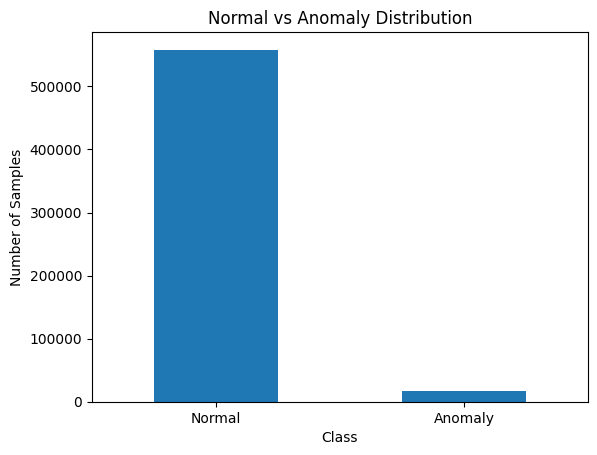

In [29]:
import matplotlib.pyplot as plt

label_counts.plot(kind="bar")

plt.title("Normal vs Anomaly Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.show()

In [30]:
# Statistical Analysis 2: Event Frequency

event_frequency = occurrence.iloc[:, 3:].sum().sort_values(ascending=False)

print("Event Frequency:")
print(event_frequency)

Event Frequency:
E5     1723232
E26    1719741
E11    1706679
E9     1706514
E21    1402047
E23    1396174
E22     575061
E3      428726
E4      356207
E2      120036
E6        7097
E18       7002
E25       7002
E16       6937
E20       5545
E7        3416
E13       1464
E28       1288
E27        975
E14        155
E10        108
E15         65
E8          49
E29         47
E12         34
E1          10
E17          9
E19          5
E24          4
dtype: int64


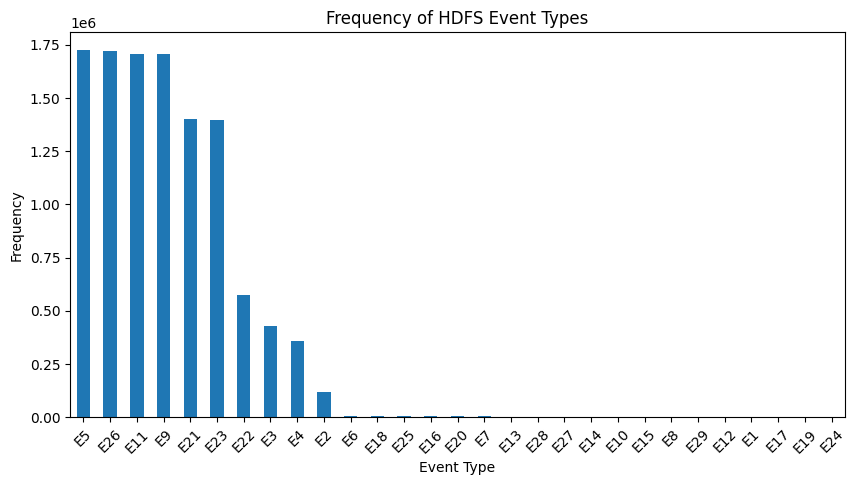

In [31]:
# Statistical Analysis 3: Event Frequency Visualization

event_frequency.plot(kind="bar", figsize=(10, 5))

plt.title("Frequency of HDFS Event Types")
plt.xlabel("Event Type")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()

## Conclusion

The HDFS dataset was successfully explored and analyzed using Python and Pandas. The dataset contains 575,061 records with 32 columns, including event-based features and anomaly labels. The analysis showed a strong class imbalance, with approximately 97.07% normal records and 2.93% anomalous records. Event-frequency analysis also showed that some event types occur much more frequently than others. These findings provide a useful foundation for applying machine learning techniques to detect anomalous system behavior in HDFS logs.

**Next Stage:** Feature preprocessing, train/test split, and training Decision Tree → Random Forest → XGBoost classifiers, evaluated with anomaly-aware metrics (precision, recall, F1-score) given the class imbalance observed above.